# How US Regions Differ in BMI and Medical Costs
- Janie Ann De Castro, Normandy Ng, Samuel Wang, Katrina Nguyen, and Samuel Wang

# Introduction

The dataset contains 1338 patients categorized into 7 different variables including age, sex, bmi, number of children, being a smoker, US region, and medical insurance costs. There is no indication whether the data is real-world collected data or simulated on the dataset Kaggle page. However, given that the medical charges column includes costs with more than two decimal points, it's likely that the data is simulated rather than real-world collected.
- Link to the source: https://www.kaggle.com/code/mragpavank/medical-cost-personal-datasets
- Question: Does the correlation between a patient's BMI and their medical insurance charges vary significantly across different regions of the US (Northwest, southwest, northeast, and southeast).
- Hypothesis: The correlation coefficient between a patient's BMI and their medical insurance charges is equal across all four regions of the US.

# Description of Data (15%)

- Columns relevant to hypothesis: bmi, region, and charges.
    - charges: Total insurance charges per patient measured in $.
        - Python / pandas datatype: numerical
        - Statistical datatype: ratio
    - bmi: Body mass index of each patient.
        - Python / pandas datatype: numerical
        - Statistical datatype: ratio
    - region: United States geographical region.
        - Python / pandas datatype: string
        - Statistical datatype: nominal


In [1]:
import pandas as pd

costs = pd.read_csv('https://raw.githubusercontent.com/greenyax/MATH5100TeamProject/master/insurance.csv')

costs.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Descriptive Statistics and Visualization (35%)
- Descriptive Statistics
    - In code, generate appropriate descriptive statistics for the columns relevant to your hypothesis.
    - In text, briefly explain the result
- Visualization
    - In code, generate a figure or figures visualizing the same data. This typically shows the distribution.
    - In text, briefly describe the figure(s) and their meaning

region
northeast    29.173503
northwest    29.199785
southeast    33.355989
southwest    30.596615
Name: bmi, dtype: float64
region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


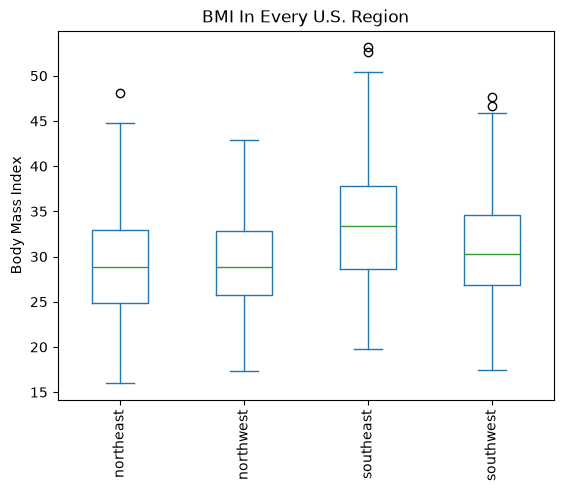

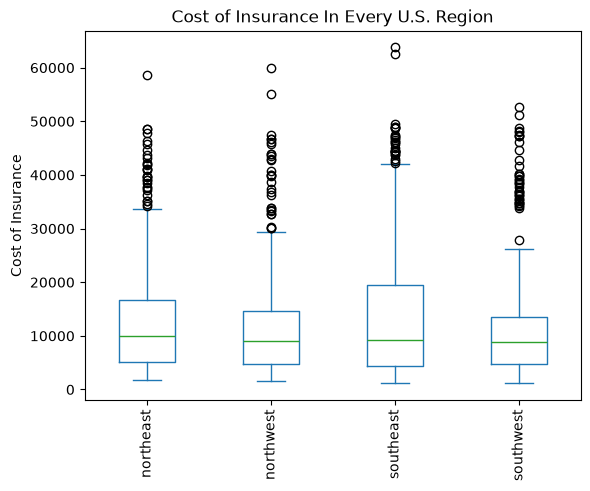

In [3]:
import matplotlib.pyplot as plt

#descriptive statistics
bmi_average = costs.groupby('region')['bmi'].mean(numeric_only=True)
print(bmi_average)

charges_average = costs.groupby('region')['charges'].mean(numeric_only=True)
print(charges_average)

#visualization
costs.plot(column='bmi', kind='box', by='region')
plt.ylabel('Body Mass Index')
plt.xticks(rotation=90)
plt.title('BMI In Every U.S. Region')
plt.show()

costs.plot(column='charges', kind='box', by='region')
plt.ylabel('Cost of Insurance')
plt.xticks(rotation=90)
plt.title('Cost of Insurance In Every U.S. Region')
plt.show()

The Southeast has both the highest average BMI and the highest average insurance charges, suggesting a possible relationship between BMI and medical costs. However, the Southwest has the second-highest average BMI but the lowest average insurance charges. This indicates that BMI alone may not explain regional differences in insurance costs. Other factors present in the dataset, such as age, smoking status, and healthcare costs, may also contribute.

In the first boxplot, it's shown that the Southeast tends to have higher BMI values than the other regions. The Northeast and Northwest have similar BMI value, while the Southwest falls between those regions and the Southeast. However, the distributions overlap quite a bit, meaning regional differences do not apply equally to every individual. In the second boxplot, it's shown that insurance charges vary by a lot within each region. Although the Southeast has the highest average charges in the descriptive statistics, the Northeast has a slightly higher median in the box plot. This difference happens because the mean is more sensitive to unusually high charges, while the median represents the middle.

# Inferential Statistics (30%)
Apply summary statistics or other statistical analysis to your dataset. More specifically, this should include:
- Text
    - name and explanation of your choice for the statistical tool to use
    - specific identification of the components of the dataset that will be applied
- Code
    - isolation of the components to be analyzed
    - application of statistical test/tool and result
- Text
    - clear statement of the meaning of the result of the stastical test

In [5]:
import pandas as pd
from scipy.stats import f_oneway, pearsonr

df = pd.read_csv("insurance.csv")

# One-way ANOVA 1: BMI across regions
nw = df[df["region"] == "northwest"]["bmi"]
sw = df[df["region"] == "southwest"]["bmi"]
ne = df[df["region"] == "northeast"]["bmi"]
se = df[df["region"] == "southeast"]["bmi"]

f, p = f_oneway(nw, sw, ne, se)

print("ANOVA for BMI")
print("F value:", f)
print("P value:", p)


# One-way ANOVA 2: Insurance charges across regions
nw = df[df["region"] == "northwest"]["charges"]
sw = df[df["region"] == "southwest"]["charges"]
ne = df[df["region"] == "northeast"]["charges"]
se = df[df["region"] == "southeast"]["charges"]

f, p = f_oneway(nw, sw, ne, se)

print("\nANOVA for Insurance Charges")
print("F value:", f)
print("P value:", p)


# Correlation for each region
for region in ["northwest", "southwest", "northeast", "southeast"]:
    group = df[df["region"] == region]
    r, p = pearsonr(group["bmi"], group["charges"])
    print(region, "correlation:", round(r, 3))

ANOVA for BMI
F value: 39.49505720170283
P value: 1.8818389139275532e-24

ANOVA for Insurance Charges
F value: 2.9696266935891193
P value: 0.03089335607049739
northwest correlation: 0.181
southwest correlation: 0.223
northeast correlation: 0.232
southeast correlation: 0.143


Based on the ANOVA results provided in the descriptive statistics, the Southeast has the highest average BMI (33.36) and highest average insurance ($14,735.41). The Northeast has the lowest average BMI (29.17) and the Southwest has the lowest average insurance ($12,346.94).

For BMI across regions, the ANOVA test produced an F-value of 39.50 and a p-value of 1.88 x 10^-24, which is substantially below the significance level of alpha = 0.05. From this data, we reject the null hypothesis and conclude that the average BMI differ significantly among the U.S. regions. For insurance charges across regions, the ANOVA test produced an F-value of 2.97 and a p-value of 0.0309, which is also below the significance level of alpha = 0.05. Therefore we also reject the null hypothesis and conclude that the average insurance charges do differ significantly across the U.S. regions.

# Concluding Summary (10%)

Write a paragraph summarizing the project including the question being answered, results of the statistics, and what can be inferred from your analysis.

Both BMI and insurance charges demonstrated statistically significant regional differences, as both p-values were below the 0.05 significance level. These results suggest that geographic region may be associated with variations in average BMI and healthcare insurance costs. These tests, however, do not determine which regions differ significantly nor whether BMI is associated with the differences in insurance charges.